# Extended MEM: Asimov discrimination of Scalar / VLF / $Z'$ (no systematics)

Implementation of `ExtendedMEM.tex`. One SM sample is reweighted to every hypothesis with
$r_H(\mathbf x)=d\sigma_H/d\sigma_{\rm SM}=1+\theta a_H+\theta^2 b_H$, and all likelihood quantities are weighted sums over its events.

| step | what | where |
|---|---|---|
| 0 | LHE $\to$ `data/events*.h5` (weights, kinematics, fluxes at 3 $\mu_F$, $\alpha_s$ at 3 $\mu_R$, generator scale weights) | `scripts/prepare_events.py` |
| 1 | matrix elements $\to$ `data/me_{Scalar,VLF,Zprime}*.h5` | `scripts/compute_me.py` |
| 2 | checks, binned reproduction of the paper, unbinned Step A / Step B | this notebook (`mem/analysis.py`) |

**Sections**
1. Sample and weight normalisation
2. Matrix-element checks
3. BSM normalisation checks
4. Binned analysis (reproduction of arXiv:2611.08459, Sec. 5)
5. Unbinned analysis (Step A, Step B)
6. Binned vs unbinned: luminosity curves, significance matrix, consistency checks
7. Monte Carlo precision and robustness

Set `EVENTS` below to the full sample (`data/events.h5`) once `compute_me.py` has finished on it; the test subsample (`events_s40.h5`, every 40th event) runs in a few minutes.

In [1]:
import json, time
import numpy as np, h5py, pandas as pd
import matplotlib.pyplot as plt
from mem import analysis as A, config as cfg, validation as V

EVENTS = "data/events.h5"              # test subsample: "data/events_s40.h5"
LUMI0 = 500.0                          # fb^-1, luminosity of the paper's fits
LUMIS = np.array([300, 500, 1000, 1500, 2000, 2500, 3000.0])
PT_BINS = np.arange(500, 3501, 100)    # paper binning (Eq. 5.13)
HYPS = ["Scalar", "VLF", "Zp01", "Zp20"]
TRUTHS = ["Scalar", "VLF", "Zp20", "Zp01"]
LABEL = {"Scalar": "Scalar", "VLF": "VLF", "Zp01": "$Z'$ narrow", "Zp20": "$Z'$ broad", "SM": "SM"}
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

S = A.Sample(EVENTS)
with h5py.File(EVENTS) as h:
    chan = h["channel"][:]
    w_lhe = h["w_lhe"][:]
    alphas0 = h["alphas0"][:]
    nvec = h["n"][:]
print(f"{len(S.w)} events, sigma = {S.sigma:.5f} pb, N_eff = {S.n_eff:.0f}")

2405738 events, sigma = 1.42876 pb, N_eff = 519073


In [2]:
# Published results (arXiv:2611.08459): Tables 2-4 (L = 500 fb^-1) and Fig. 12 (L = 3 ab^-1).
# theta = y_DM^2 (Scalar, VLF) or g_q g_t (Z').
PAPER_FITS = {
    "Scalar": {"Scalar": (1510.2, 7.6**2, 0.009), "VLF": (1744.5, 4.6**2, 0.85),
               "Zp01": (2500.1, -0.016*0.35, 23.3), "Zp20": (2882.0, -0.030*1.58, 10.5)},
    "VLF":    {"VLF": (1505.3, 3.8**2, 0.008), "Scalar": (1247.0, 5.9**2, 0.83),
               "Zp01": (2908.9, -0.019*0.35, 22.2), "Zp20": (2811.0, -0.028*1.58, 9.3)},
    "Zp20":   {"Zp20": (3009.8, -0.034*1.58, 0.06), "Zp01": (2915.9, -0.023*0.35, 11.0),
               "VLF": (1518.0, 3.6**2, 11.2), "Scalar": (1336.1, 6.0**2, 10.3)},
}
PAPER_YIELD = {"Scalar": ("Scalar", 1510.2, 7.6**2, 3032), "VLF": ("VLF", 1505.3, 3.8**2, 3465),
               "Zp20": ("Zp20", 3009.8, -0.034*1.58, 1372)}       # signal events in 0.5 < pT < 3.5 TeV, 500 fb^-1
PAPER_Z3000 = {  # [H0][H1]
    "Scalar": {"VLF": 2.2, "Zp01": 12.5, "Zp20": 7.8}, "VLF": {"Scalar": 2.2, "Zp01": 12.4, "Zp20": 8.2},
    "Zp01": {"Scalar": 11.7, "VLF": 11.5, "Zp20": 8.0}, "Zp20": {"Scalar": 7.9, "VLF": 7.5, "Zp01": 9.4}}

## 1. Sample and weight normalisation

The SM sample is a fixed-order aMC@NLO run (`[QCD NP]` at $y_{\rm DM}=0$, i.e. the LO Born) with an $m_{t\bar t}$ bias, signed NNPDF2.3 PDFs, and $\mu_R=\mu_F=H_T/2$.

**Finding.** Within each integration channel the LHE weights have the correct, unbiased shape, but in each channel they sum to that channel's *biased* cross section (`res_*.txt`). A single $\kappa=\sigma/\sum w^{\rm LHE}$ therefore over-weights $q\bar q$ relative to $gg$ by about 7.5%, and the $p_T$ spectrum is distorted by up to 4% (the $q\bar q$ events are more central). The weights are normalised per channel instead:
$w_j=\kappa_c w_j^{\rm LHE}$, $\kappa_c=\sigma_c/\sum_{j\in c}w^{\rm LHE}_j$, with $\sigma_c$ from an independent LO integration (`mem/validation.py`), whose total is checked against `summary.txt`.

In [3]:
norm = S.meta["norm"]
print(json.dumps({k: norm[k] for k in ("sigma_summary", "sigma_lo", "sigma_lo_err", "kappa")}, indent=1))
print(f"sigma_LO total = {sum(norm['sigma_lo'].values()):.5f} pb   vs summary.txt {norm['sigma_summary']} pb")
Ss = A.Sample(EVENTS, flux_mode="signed")
print(f"generator (signed PDFs): negative-weight events {np.mean(Ss.w < 0):.2%}, share of sigma "
      f"{Ss.w[Ss.w < 0].sum() / Ss.sigma:.1e}, median max(x1,x2) {np.median(np.maximum(Ss.x1, Ss.x2)[Ss.w < 0]):.2f}")
print(f"nominal (|f_a f_b|): sigma = {S.sigma:.5f} pb, min weight {S.w.min():.1e}, "
      f"r_T(Scalar) in [{S.r_benchmark('Scalar').min():.3f}, {S.r_benchmark('Scalar').max():.3f}] "
      f"(signed: up to {Ss.r_benchmark('Scalar').max():.3g})")

{
 "sigma_summary": 1.424,
 "sigma_lo": {
  "gg": 0.9764899359011249,
  "qq": 0.4496284719499506
 },
 "sigma_lo_err": {
  "gg": 0.0007406363048525443,
  "qq": 0.0002680426337974907
 },
 "kappa": {
  "gg": 9.778483997386129,
  "qq": 8.901427430475005
 }
}
sigma_LO total = 1.42612 pb   vs summary.txt 1.424 pb


generator (signed PDFs): negative-weight events 2.22%, share of sigma -4.2e-04, median max(x1,x2) 0.76


nominal (|f_a f_b|): sigma = 1.42876 pb, min weight 1.5e-30, r_T(Scalar) in [0.784, 1.166] (signed: up to 10.2)


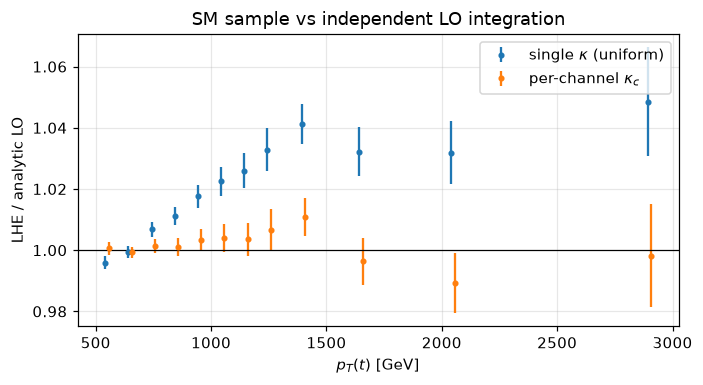

In [4]:
# Independent LO integration (cached): shape test of the two normalisations against it
import os
bins = np.array([500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1500, 1800, 2300, 3500.])
cache = "data/lo_integration_pt.npz"   # LO histogram, 16M points, NO m_tt ceiling (must match the generation cuts)
c = np.load(cache) if os.path.exists(cache) else None
if c is None or len(c["bins"]) != len(bins) or not np.allclose(c["bins"], bins):
    lo = V.lo_integration(16_000_000, seed=7)        # about 2 min
    np.savez(cache, *V.hist_with_err(lo["pt"], lo["w"], bins), bins=bins)
    c = np.load(cache)
h_lo, e_lo = c["arr_0"], c["arr_1"]
w_single = w_lhe * norm["sigma_summary"] / w_lhe.sum()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
xc = 0.5 * (bins[1:] + bins[:-1])
for w, lab, off in [(w_single, r"single $\kappa$ (uniform)", -8), (Ss.w, r"per-channel $\kappa_c$", 8)]:
    h, e = V.hist_with_err(Ss.pt, w, bins)
    ax.errorbar(xc + off, h / h_lo, yerr=np.hypot(e / h, e_lo / h_lo) * h / h_lo, fmt="o", ms=3, label=lab)
ax.axhline(1, c="k", lw=0.8); ax.set_xlabel(r"$p_T(t)$ [GeV]"); ax.set_ylabel("LHE / analytic LO"); ax.legend()
ax.set_title("SM sample vs independent LO integration"); plt.tight_layout()

## 2. Matrix-element checks

* the MadLoop Born against the analytic LO formulas, and the Scalar library against the VLF library;
* the $\mu_R$ independence of $\rho_c=I_c/|M_{\rm SM}|^2$ (exact $\alpha_s^2$ scaling, which the scale variations rely on);
* beam-swap symmetry of the $q\bar q$ interference (so the two orientations combine into $F_q$);
* the $Z'$ Breit-Wigner factorisation $B=K/D$, $A=[(\hat s-M^2)R+M\Gamma I]/D$: a direct evaluation at $(M,\Gamma)$ points not used in the extraction;
* MadLoop stability flags and re-evaluation of the first events (first-call artefacts).

Two MadGraph pitfalls were found while building the libraries. They are handled in `mem/mg.py` and in the patched `processFolders/z_prime/MatrixElements/Zprime_*`:
(i) in the standalone LO output, `JAMP(2,2)` is never assigned, so uninitialised memory entered the colour sum of the $Z'$ interference. The fix zeroes `JAMP` (the MadEvent code used for the paper's samples already does this);
(ii) two MadGraph libraries loaded in the same Python process share Fortran symbols, so each worker loads only one.

In [5]:
rows = []
gg_an, qq_an = V.born_lo(S.mtt, nvec[S.mask, 2], alphas0[S.mask])
with h5py.File(S.me_file("Scalar")) as hs, h5py.File(S.me_file("VLF")) as hv, h5py.File(S.me_file("Zprime")) as hz:
    bs, bv = hs["born"][:][S.mask], hv["born"][:][S.mask]
    rows.append(("Born gg: MadLoop / analytic - 1", np.max(np.abs(bs[:, 0] / gg_an - 1))))
    rows.append(("Born qq: MadLoop / analytic - 1", np.max(np.abs(bs[:, 1] / qq_an - 1))))
    rows.append(("Born: Scalar lib / VLF lib - 1", np.max(np.abs(bs / bv - 1))))
    for name, h in (("Scalar", hs), ("VLF", hv)):
        i0 = 0
        for ch in ("gg", "qq"):
            st = h[f"checks/scale_{ch}"][:]
            rows.append((f"{name} rho_{ch}(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",
                         np.max(np.abs(st / h[f"rho_{ch}"][i0, :len(st)][:, None] - 1))))
        sw = h["checks/swap_qq"][:]
        rows.append((f"{name} qq beam swap: rho(p2,p1)/rho(p1,p2) - 1", np.max(np.abs(sw[1, 1] / sw[0, 1] - 1))))
        rows.append((f"{name} unstable MadLoop points (flag)", int(h["flag"][:].sum())))
        rows.append((f"{name} max re-evaluation deviation", h.attrs["recheck_max"]))
    rows.append(("Z' max deviation from Breit-Wigner form", hz.attrs["bw_dev_max"]))
pd.DataFrame(rows, columns=["check", "value"])

,check,value
0,Born gg: MadLoop / analytic - 1,8.4896e-07
1,Born qq: MadLoop / analytic - 1,1.3989e-14
2,Born: Scalar lib / VLF lib - 1,5.5511e-16
3,"Scalar rho_gg(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8007e-08
4,"Scalar rho_qq(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8367e-08
5,"Scalar qq beam swap: rho(p2,p1)/rho(p1,p2) - 1",4.0367e-10
6,Scalar unstable MadLoop points (flag),0.0000e+00
7,Scalar max re-evaluation deviation,5.8311e-08
8,"VLF rho_gg(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.8212e-08
9,"VLF rho_qq(mu_R = mu0/2, 2mu0) / rho(mu0) - 1",5.6849e-08


## 3. BSM normalisation checks

**(a) Against the paper.** Signal yields in $0.5<p_T<3.5$ TeV at 500 fb$^{-1}$ (Tables 2-4), evaluated at the paper's best-fit parameters of the true model. Our sample also has the generation cut $m_{t\bar t}<4.6$ TeV, so it has no events above $p_T\simeq2.3$ TeV.

**(b) Against the Scalar aMC@NLO run** of the same benchmark (`processFolders/Scalar/pp2ttbar_gs4_ydm2/Events/bias_13_6TeV_fiducial_pT`). Its precise numbers are the *biased* totals $\int b\,d\sigma$ (0.07% MC error): $b(m_{t\bar t})$ is the bias of that folder with $m_{\tilde t}=1500$ GeV, which reproduces the SM biased total. Its histogram value (1.429 pb) is rounded to $10^{-3}$.

In [6]:
rows = []
for truth, (model, M, th, y_paper) in PAPER_YIELD.items():
    r = S.r(model, th, M)
    y = A.FB * LUMI0 * np.sum(S.w * (r - 1))
    rows.append((truth, M, th, y_paper, y, y / y_paper))
pd.DataFrame(rows, columns=["truth", "M", "theta", "paper yield", "this work", "ratio"])

,truth,M,theta,paper yield,this work,ratio
0,Scalar,1510.2,57.7600,3032,3156.6438,1.0411
1,VLF,1505.3,14.4400,3465,3554.3943,1.0258
2,Zp20,3009.8,-0.0537,1372,1339.4272,0.9763


In [7]:
def bias_scalar(mtt, mst=1500.0):     # Source/mtt_bias_NLO.f of the Scalar folder (peak_loc > 2900 branch)
    pk = 2.05 * mst
    b1, b2, d3 = 3510 / 3075 * pk, 3770 / 3075 * pk, 3207 / 3075 * pk
    return np.where(mtt < b1, (mtt / pk) ** 3.3, np.where(mtt < b2, (mtt / pk) ** 2.0, (mtt / d3) ** 8.0))

b = bias_scalar(S.mtt); rT = S.r_benchmark("Scalar")
# res_1.txt of the two runs (no m_tt ceiling in either)
amc = {"SM": {"gg": 0.0998611, "qq": 0.0252763 + 0.0252356}, "Scalar": {"gg": 0.0998529, "qq": 0.0262219 + 0.0261851}}
rows = []
with h5py.File(S.me_file("Scalar")) as h:
    i = list(h.attrs["masses"]).index(1500)
    rho = {"gg": h["rho_gg"][i][S.mask], "qq": h["rho_qq"][i][S.mask]}
for ch, frac in (("gg", S.omega_gg), ("qq", 1 - S.omega_gg)):
    sm = S.w * b * frac
    bsm = sm * cfg.BENCHMARKS["Scalar"]["theta"] * rho[ch]
    rows.append((ch, sm.sum(), amc["SM"][ch], bsm.sum() / sm.sum(), amc["Scalar"][ch] / amc["SM"][ch] - 1))
pd.DataFrame(rows, columns=["channel", "biased SM (this)", "biased SM (aMC)", "BSM/SM biased (this)", "BSM/SM biased (aMC)"])

,channel,biased SM (this),biased SM (aMC),BSM/SM biased (this),BSM/SM biased (aMC)
0,gg,0.1001,0.0999,0.0002,-8.2114e-05
1,qq,0.0513,0.0505,0.0404,3.7518e-02


Both channels agree: the BSM effect of the aMC@NLO Scalar run (+3.8% in $q\bar q$, compatible with 0 in $gg$, in biased units) is reproduced by the MadLoop matrix elements used here. Both runs must have the same cuts for this comparison. An earlier SM run had an $m_{t\bar t}<4.6$ TeV ceiling that the Scalar run did not have, and that mismatch made the aMC@NLO BSM effect look twice as large.

## 4. Binned analysis: reproduction of the paper

Same events, but the cells are the paper's $p_T$ bins. Step A minimises the binned Poisson deviance (paper Eq. 5.1-5.5); Step B is Eq. 5.9. The masses come from a profile over the 100 GeV grid with a parabola through the three lowest points.

In [8]:
def run_all(bins, lumi=LUMI0, sample=S, truths=TRUTHS):
    # all truths in parallel (forked processes sharing the per-event coefficients)
    t0 = time.time()
    out = A.run_truths(sample, truths, HYPS + ["SM"], lumi=lumi, bins=bins)
    print(f"  {len(truths)} truths done in {time.time() - t0:.0f}s")
    return out

def fit_table(res, truth, paper=True):
    rows = []
    for h in HYPS:
        f = res[truth]["fits"][h]
        row = dict(hypothesis=h, M=f["M"], theta=f["theta"], chi2=f["chi2"])
        if paper and truth in PAPER_FITS and h in PAPER_FITS[truth]:
            Mp, tp, cp = PAPER_FITS[truth][h]
            row.update(M_paper=Mp, theta_paper=tp, chi2_paper=cp)
        rows.append(row)
    return pd.DataFrame(rows).set_index("hypothesis")

print("binned:"); RB = run_all(PT_BINS)

binned:


  4 truths done in 7s


In [9]:
for t in ["Scalar", "VLF", "Zp20"]:
    print(f"truth = {t}  (binned, L = {LUMI0:.0f} fb^-1)")
    display(fit_table(RB, t))

truth = Scalar  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1500.0000,56.2500,-4.6355e-11,1510.2,57.7600,0.009
VLF,1746.6865,20.7082,8.1294e-01,1744.5,21.1600,0.850
Zp01,2700.0000,-0.0063,2.3715e+01,2500.1,-0.0056,23.300
Zp20,2942.4406,-0.0477,1.0949e+01,2882.0,-0.0474,10.500


truth = VLF  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1252.8528,35.259,8.6400e-01,1247.0,34.8100,0.830
VLF,1500.0000,14.440,-1.0621e-10,1505.3,14.4400,0.008
Zp01,2900.0000,-0.007,2.2681e+01,2908.9,-0.0066,22.200
Zp20,2813.5708,-0.045,1.0171e+01,2811.0,-0.0442,9.300


truth = Zp20  (binned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1300.0,34.0566,1.0823e+01,1336.1,36.0000,10.30
VLF,1500.0,12.2733,1.1802e+01,1518.0,12.9600,11.20
Zp01,2900.0,-0.0086,9.1723e+00,2915.9,-0.0080,11.00
Zp20,3000.0,-0.0553,-5.5585e-11,3009.8,-0.0537,0.06


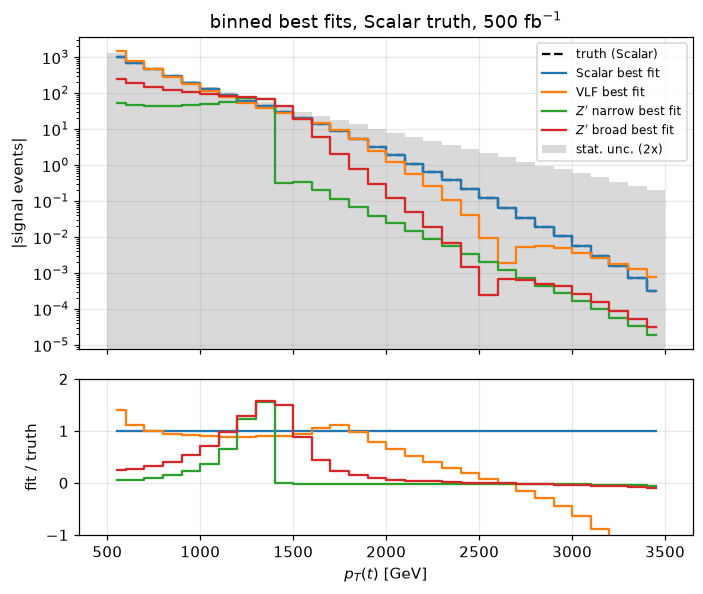

In [10]:
def plot_fig9(res, truth, title):
    # Fig. 9 analogue: BSM p_T distribution of the best fits, ratio to the truth
    cells = A.Cells(S, PT_BINS)
    nT = cells.counts(S.r_benchmark(truth) - 1) * A.FB * LUMI0
    ntot = cells.counts(S.r_benchmark(truth)) * A.FB * LUMI0
    xc = 0.5 * (PT_BINS[1:] + PT_BINS[:-1])
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(6.5, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    a0.bar(xc, 2 * np.sqrt(np.abs(ntot)), width=100, color="0.85", label="stat. unc. (2x)")
    a0.step(xc, np.abs(nT), where="mid", c="k", ls="--", label=f"truth ({LABEL[truth]})")
    for h in HYPS:
        f = res[truth]["fits"][h]
        n = cells.counts(A.r_of(S, f) - 1) * A.FB * LUMI0
        a0.step(xc, np.abs(n), where="mid", label=f"{LABEL[h]} best fit")
        with np.errstate(divide="ignore", invalid="ignore"):
            a1.step(xc, n / nT, where="mid")
    a0.set_yscale("log"); a0.set_ylabel("|signal events|"); a0.legend(fontsize=8); a0.set_title(title)
    a1.set_ylim(-1, 2); a1.set_xlabel(r"$p_T(t)$ [GeV]"); a1.set_ylabel("fit / truth"); plt.tight_layout()

plot_fig9(RB, "Scalar", "binned best fits, Scalar truth, 500 fb$^{-1}$")

## 5. Unbinned analysis (Step A, Step B)

One cell per event: $\chi^2_H=2L\sum_j w_j[r_H-r_T+r_T\ln(r_T/r_H)]$ and $q_A=2L\sum_j w_j[r_0-r_1+r_1\ln(r_1/r_0)]$.

In [11]:
print("unbinned:"); RU = run_all(None)
for t in ["Scalar", "VLF", "Zp20"]:
    print(f"truth = {t}  (unbinned, L = {LUMI0:.0f} fb^-1)")
    display(fit_table(RU, t))

unbinned:


  4 truths done in 73s
truth = Scalar  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1500.0000,56.2500,-1.7369e-13,1510.2,57.7600,0.009
VLF,1744.5182,20.6310,1.3627e+00,1744.5,21.1600,0.850
Zp01,3300.0000,-0.0029,3.9333e+01,2500.1,-0.0056,23.300
Zp20,3219.9110,-0.0486,1.6873e+01,2882.0,-0.0474,10.500


truth = VLF  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1290.1967,37.8763,1.8729e+00,1247.0,34.8100,0.830
VLF,1500.0000,14.4400,-2.2578e-13,1505.3,14.4400,0.008
Zp01,3036.7616,-0.0030,3.7813e+01,2908.9,-0.0066,22.200
Zp20,3009.5148,-0.0454,1.3508e+01,2811.0,-0.0442,9.300


truth = Zp20  (unbinned, L = 500 fb^-1)


,M,theta,chi2,M_paper,theta_paper,chi2_paper
hypothesis,,,,,,
Scalar,1300.0000,36.5485,2.1400e+01,1336.1,36.0000,10.30
VLF,1500.0000,13.6944,1.9302e+01,1518.0,12.9600,11.20
Zp01,3009.1193,-0.0040,4.6538e+01,2915.9,-0.0080,11.00
Zp20,3000.0000,-0.0553,-8.3521e-14,3009.8,-0.0537,0.06


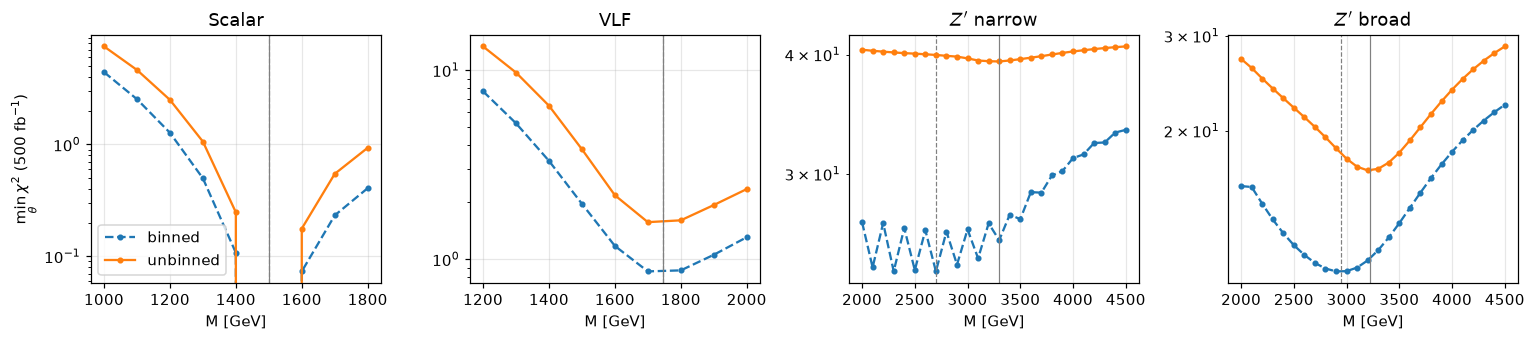

In [12]:
# Step-A profiles chi^2(M) (theta profiled), binned vs unbinned, Scalar truth
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, h in zip(axs, HYPS):
    for res, lab, ls in ((RB, "binned", "--"), (RU, "unbinned", "-")):
        f = res["Scalar"]["fits"][h]
        ax.plot(f["grid"], f["profile"][:, 1], ls, marker=".", label=lab)
        ax.axvline(f["M"], ls=ls, c="0.5", lw=0.8)
    ax.set_title(LABEL[h]); ax.set_xlabel("M [GeV]"); ax.set_yscale("log")
axs[0].set_ylabel(r"$\min_\theta \chi^2$ (500 fb$^{-1}$)"); axs[0].legend(); plt.tight_layout()

## 6. Binned vs unbinned

Without systematics $q_A\propto L$, so $Z_A(L)=Z_A(L_0)\sqrt{L/L_0}$ and the best fits do not depend on $L$.

In [13]:
def z_table(res, lumi):
    return pd.DataFrame({LABEL[t]: {LABEL[h]: z * np.sqrt(lumi / LUMI0) for h, z in res[t]["Z"].items()}
                         for t in res}).loc[[LABEL[h] for h in HYPS + ["SM"]]]

print("Z_A at 500 fb^-1  [rows: tested H0, columns: truth H1]")
display(pd.concat({"binned": z_table(RB, 500), "unbinned": z_table(RU, 500)}, axis=1))
print("Z_A at 3 ab^-1")
paper = pd.DataFrame({LABEL[t]: {LABEL[h]: PAPER_Z3000[h].get(t, np.nan) for h in HYPS} for t in TRUTHS})
display(pd.concat({"paper (Fig. 12)": paper, "binned": z_table(RB, 3000).loc[paper.index],
                   "unbinned": z_table(RU, 3000).loc[paper.index]}, axis=1))

Z_A at 500 fb^-1  [rows: tested H0, columns: truth H1]


binned                                unbinned          \
             Scalar     VLF $Z'$ broad $Z'$ narrow   Scalar     VLF   
Scalar          NaN  0.9295     3.2898      1.0861      NaN  1.3685   
VLF          0.9016     NaN     3.4354      1.0735   1.1674     NaN   
$Z'$ narrow  4.8698  4.7624     3.0286         NaN   6.2716  6.1493   
$Z'$ broad   3.3090  3.1891        NaN      0.7631   4.1076  3.6753   
SM           6.0029  6.0041     6.1861      1.3034   6.4362  6.4567   

                                    
            $Z'$ broad $Z'$ narrow  
Scalar          4.6260      3.6530  
VLF             4.3934      3.5808  
$Z'$ narrow     6.8219         NaN  
$Z'$ broad         NaN      3.3698  
SM              7.5860      3.7565

Z_A at 3 ab^-1


paper (Fig. 12)                                binned           \
                     Scalar   VLF $Z'$ broad $Z'$ narrow   Scalar      VLF   
Scalar                  NaN   2.2        7.8        12.5      NaN   2.2768   
VLF                     2.2   NaN        8.2        12.4   2.2085      NaN   
$Z'$ narrow            11.7  11.5        8.0         NaN  11.9286  11.6655   
$Z'$ broad              7.9   7.5        NaN         9.4   8.1053   7.8118   

                                   unbinned                                  
            $Z'$ broad $Z'$ narrow   Scalar      VLF $Z'$ broad $Z'$ narrow  
Scalar          8.0584      2.6603      NaN   3.3522    11.3314      8.9480  
VLF             8.4150      2.6296   2.8594      NaN    10.7617      8.7712  
$Z'$ narrow     7.4185         NaN  15.3622  15.0625    16.7101         NaN  
$Z'$ broad         NaN      1.8692  10.0616   9.0026        NaN      8.2543

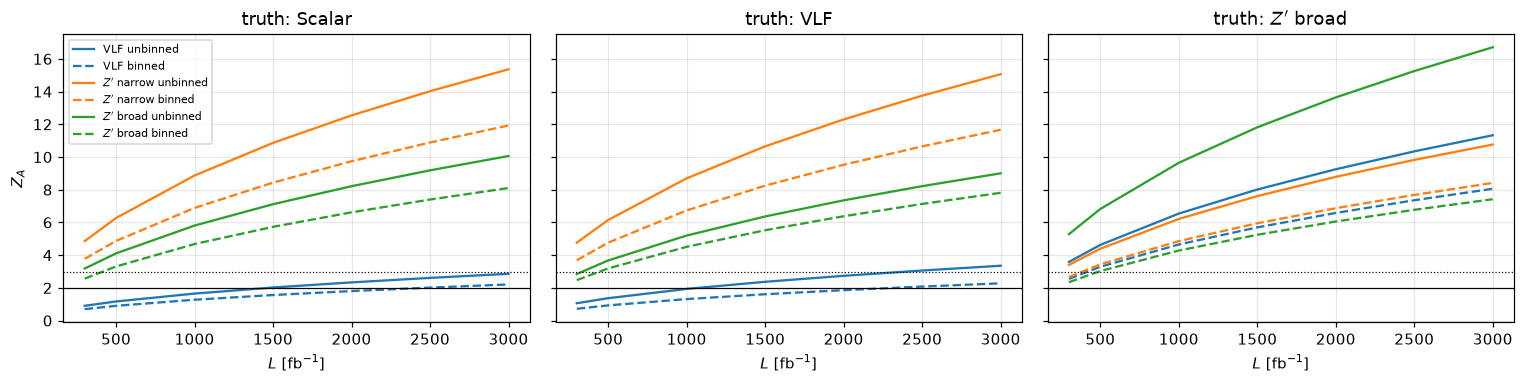

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, t in zip(axs, ["Scalar", "VLF", "Zp20"]):
    for k, h in enumerate([h for h in HYPS if h != t]):
        c = f"C{k}"
        ax.plot(LUMIS, RU[t]["Z"][h] * np.sqrt(LUMIS / LUMI0), c=c, label=f"{LABEL[h]} unbinned")
        ax.plot(LUMIS, RB[t]["Z"][h] * np.sqrt(LUMIS / LUMI0), c=c, ls="--", label=f"{LABEL[h]} binned")
    ax.axhline(2, c="k", lw=0.8); ax.axhline(3, c="k", lw=0.8, ls=":")
    ax.set_title(f"truth: {LABEL[t]}"); ax.set_xlabel(r"$L$ [fb$^{-1}$]")
axs[0].set_ylabel(r"$Z_A$"); axs[0].legend(fontsize=7); plt.tight_layout()

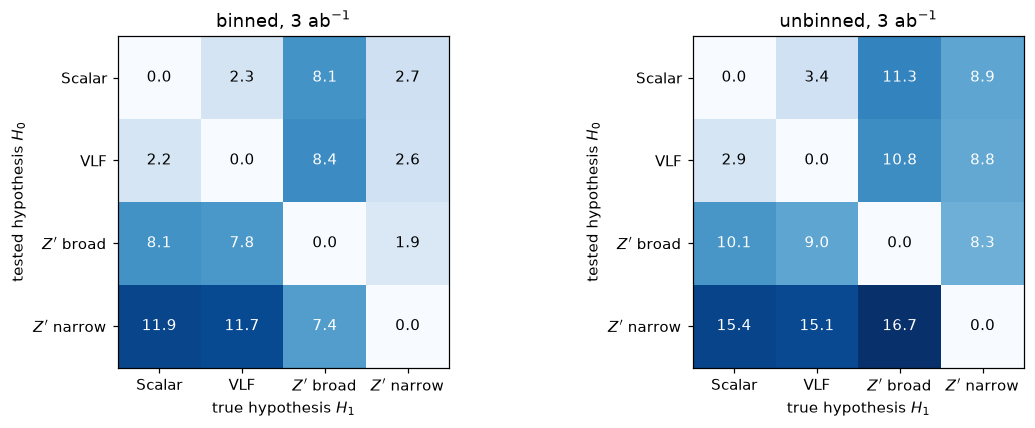

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, res, title in ((axs[0], RB, "binned"), (axs[1], RU, "unbinned")):
    M = np.array([[0.0 if h == t else res[t]["Z"][h] * np.sqrt(3000 / LUMI0) for t in TRUTHS] for h in TRUTHS])
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=max(13, M.max()))
    for i in range(len(TRUTHS)):
        for j in range(len(TRUTHS)):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", color="w" if M[i, j] > 7 else "k")
    ax.set_xticks(range(4), [LABEL[t] for t in TRUTHS]); ax.set_yticks(range(4), [LABEL[t] for t in TRUTHS])
    ax.set_xlabel("true hypothesis $H_1$"); ax.set_ylabel("tested hypothesis $H_0$"); ax.grid(False)
    ax.set_title(f"{title}, 3 ab$^{{-1}}$")
plt.tight_layout()

### Consistency checks

1. **Log-sum inequality.** For the *same* pair $(r_0, r_1)$, the unbinned $q_A$ must be at least the binned one (exact for positive weights, which holds in the nominal $|f_af_b|$ convention).
2. **Step-B Asimov data.** $r_1$ (truth model at its own best fit) vs the benchmark $r_T$: identical up to the truth's best-fit deviance.
3. **Mixed analysis.** Binned Step-A fits with unbinned $q_A$, which separates the gain coming from the fit from the gain coming from the test.

In [16]:
cb, cu = A.Cells(S, PT_BINS), A.Cells(S, None)
rows = []
for t in ["Scalar", "VLF", "Zp20"]:
    r1u = RU[t]["r1"]; rT = S.r_benchmark(t)
    for h in [h for h in HYPS + ["SM"] if h != cfg.BENCHMARKS[t]["model"]]:
        r0 = A.r_of(S, RB[t]["fits"][h])                         # binned best fit of H0
        r1b = RB[t]["r1"]
        qb, qu = A.q_asimov(cb, r0, r1b, LUMI0), A.q_asimov(cu, r0, r1b, LUMI0)
        qT = A.q_asimov(cu, A.r_of(S, RU[t]["fits"][h]), rT, LUMI0)
        rows.append(dict(truth=t, H0=h, Z_binned=np.sqrt(qb), Z_unbinned_same_fits=np.sqrt(qu),
                         inequality_ok=qu >= qb * (1 - 1e-6), Z_unbinned=RU[t]["Z"][h], Z_unbinned_rT=np.sqrt(qT)))
pd.DataFrame(rows)

,truth,H0,Z_binned,Z_unbinned_same_fits,inequality_ok,Z_unbinned,Z_unbinned_rT
0,Scalar,VLF,0.9016,1.1664,True,1.1674,1.1674
1,Scalar,Zp01,4.8698,10.9225,True,6.2716,6.2716
2,Scalar,Zp20,3.3090,4.4490,True,4.1076,4.1076
3,Scalar,SM,6.0029,6.4362,True,6.4362,6.4362
4,VLF,Scalar,0.9295,1.4012,True,1.3685,1.3685
5,VLF,Zp01,4.7624,10.5533,True,6.1493,6.1493
6,VLF,Zp20,3.1891,4.1179,True,3.6753,3.6753
7,VLF,SM,6.0041,6.4567,True,6.4567,6.4567
8,Zp20,Scalar,3.2898,4.6438,True,4.6260,4.6260
9,Zp20,VLF,3.4354,4.4391,True,4.3934,4.3934


## 7. Monte Carlo precision and robustness

* $N_{\rm eff}=(\sum w)^2/\sum w^2$ and a Poisson bootstrap of the events at fixed best fits (the spread of $Z_A$ from the finite MC sample).
* PDF convention (not a variation run here): the nominal analysis uses $|f_af_b|$ per ordered pair (MadEvent, `ExtendedMEM.tex`), converting each generator weight with $D^{\rm abs}_c/D^{\rm signed}_c$ of its own integration channel ($gg$, $q\bar q$ with the quark from beam 1, or from beam 2: each generated event comes from one oriented channel). The signed products the generator sampled are not a usable variation: where the negative large-$x$ gluon cancels the $q\bar q$ term, $D_{\rm SM}\to0$ and $r_H$ blows up (a PDF artefact; on the full sample the deviance becomes infinite).
* a large-$x$ cut, $\max(x_1,x_2)<0.4$, which removes the region where the NNPDF2.3 densities are negative and poorly constrained.

In [17]:
print(f"N = {len(S.w)},  N_eff = {S.n_eff:.0f},  N_eff(pT > 1.2 TeV) = "
      f"{S.w[S.pt > 1200].sum()**2 / np.sum(S.w[S.pt > 1200]**2):.0f}")
rows = []
for t in ["Scalar", "VLF", "Zp20"]:
    for h in [h for h in HYPS if h != cfg.BENCHMARKS[t]["model"]]:
        qb = A.bootstrap_q(cu, A.r_of(S, RU[t]["fits"][h]), RU[t]["r1"], LUMI0, nboot=100)
        zb = np.sqrt(np.clip(qb, 0, None))
        rows.append(dict(truth=t, H0=h, Z=RU[t]["Z"][h], Z_boot_mean=zb.mean(), Z_boot_std=zb.std()))
pd.DataFrame(rows)

N = 2405738,  N_eff = 519073,  N_eff(pT > 1.2 TeV) = 123168


,truth,H0,Z,Z_boot_mean,Z_boot_std
0,Scalar,VLF,1.1674,1.1673,0.0011
1,Scalar,Zp01,6.2716,6.2713,0.0040
2,Scalar,Zp20,4.1076,4.1076,0.0022
3,VLF,Scalar,1.3685,1.3685,0.0016
4,VLF,Zp01,6.1493,6.1492,0.0037
5,VLF,Zp20,3.6753,3.6752,0.0019
6,Zp20,Scalar,4.6260,4.6256,0.0061
7,Zp20,VLF,4.3934,4.3930,0.0046
8,Zp20,Zp01,6.8219,6.8212,0.0091


In [18]:
variants = {"nominal": S, "max(x1,x2) < 0.4": A.Sample(EVENTS, xcut=0.4)}
tabs = {}
for name, smp in variants.items():
    if name == "nominal":
        res = RU
    else:
        print(name); res = run_all(None, sample=smp, truths=["Scalar", "VLF", "Zp20"])
    tabs[name] = z_table(res, 3000)[[LABEL[t] for t in ["Scalar", "VLF", "Zp20"]]]
print("unbinned Z_A at 3 ab^-1 (fits redone in each variant)")
pd.concat(tabs, axis=1)

max(x1,x2) < 0.4


  3 truths done in 46s
unbinned Z_A at 3 ab^-1 (fits redone in each variant)


nominal                     max(x1,x2) < 0.4                    
              Scalar      VLF $Z'$ broad           Scalar      VLF $Z'$ broad
Scalar           NaN   3.3522    11.3314              NaN   2.7041     9.4241
VLF           2.8594      NaN    10.7617           2.3770      NaN     9.2195
$Z'$ narrow  15.3622  15.0625    16.7101          12.8178  13.0105    13.5963
$Z'$ broad   10.0616   9.0026        NaN           8.5345   8.1657        NaN
SM           15.7653  15.8157    18.5819          13.1383  13.6052    15.1208